# phân tích dữ liệu (EDA)

## thư viện sử dụng

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
path = Path(r"..\..\data\raw\train.csv")

df = pd.read_csv(path)
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## loại bỏ ID vì không có ý nghĩa phân tích

In [5]:
df=df.drop(columns='Id')

## phân phối của biến Target

<Axes: xlabel='SalePrice', ylabel='Count'>

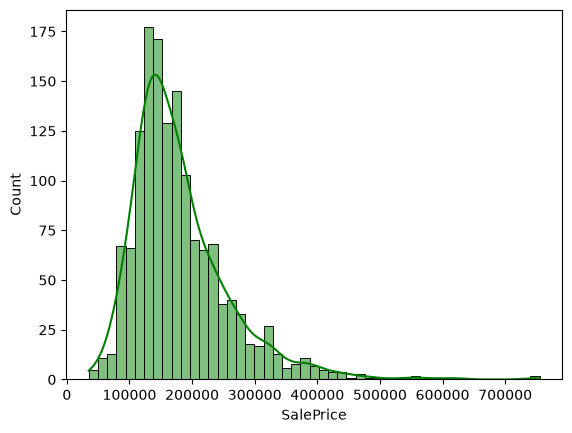

In [8]:
sns.histplot(data=df,x='SalePrice',color='g',kde=True)

**Nhận xét:** Biểu đồ thể hiện phân phối giá bán nhà (`SalePrice`). Quan sát vị trí tập trung của các cột để xác định khoảng giá phổ biến; nếu đuôi phân phối kéo dài về bên phải, dữ liệu có độ lệch phải và có một số căn nhà giá cao hơn đáng kể so với phần lớn mẫu.

<Axes: xlabel='SalePrice', ylabel='Count'>

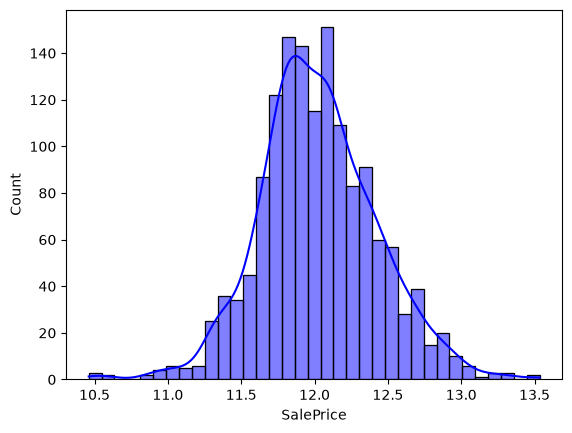

In [9]:
log_saleprice=np.log1p(df['SalePrice'])
sns.histplot(data=log_saleprice,color='b',kde=True)

**Nhận xét:** Sau phép biến đổi `log1p`, các giá trị giá bán được nén lại ở phía cao. So sánh biểu đồ này với phân phối ban đầu để đánh giá mức độ giảm lệch và xem dữ liệu có trở nên cân đối hơn hay không. Biến đổi log có thể hữu ích khi phân tích hoặc xây dựng mô hình.

In [15]:
target = "SalePrice"
num_cols = df.select_dtypes(include="number").columns

corr_target = (
    df[num_cols]
    .corr(method="pearson")[target]
    .drop(target)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(corr_target.to_frame("corr_with_SalePrice"))

,corr_with_SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


**Nhận xét:** Bảng sắp xếp các biến số theo độ lớn tuyệt đối của tương quan Pearson với `SalePrice`. Hệ số dương cho thấy hai biến có xu hướng tăng cùng chiều; hệ số âm thể hiện xu hướng ngược chiều. Giá trị càng gần -1 hoặc 1 thì quan hệ tuyến tính càng mạnh, còn gần 0 là tương quan tuyến tính yếu. Tương quan không đồng nghĩa với quan hệ nhân quả.

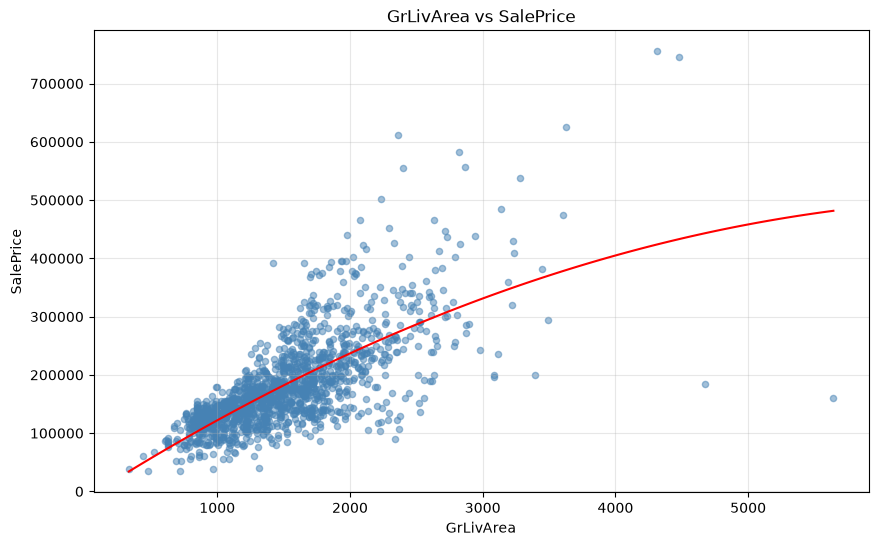

In [19]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    order=2,  # Polynomial Regression bậc 2
    ci=None,
    scatter_kws={
        "alpha": 0.5,
        "s": 20,
        "color": "steelblue"
    },
    line_kws={
        "color": "red",
        "linewidth": 1.5
    }
)

plt.title("GrLivArea vs SalePrice")
plt.xlabel("GrLivArea")
plt.ylabel("SalePrice")
plt.grid(alpha=0.3)


**Nhận xét:** Biểu đồ đối chiếu diện tích sinh hoạt trên mặt đất (`GrLivArea`) với giá bán (`SalePrice`). Quan sát xu hướng của các điểm và đường hồi quy: xu hướng đi lên cho thấy diện tích lớn thường đi kèm giá bán cao hơn. Các điểm nằm xa cụm chính có thể là trường hợp ngoại lệ cần kiểm tra thêm.

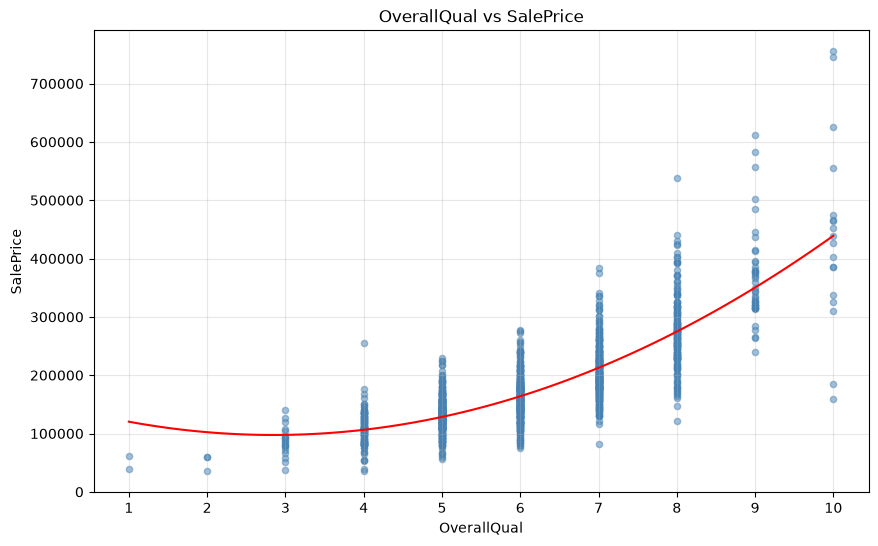

In [20]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="OverallQual",
    y="SalePrice",
    order=2,
    ci=None,
    scatter_kws={
        "alpha": 0.5,
        "s": 20,
        "color": "steelblue"
    },
    line_kws={
        "color": "red",
        "linewidth": 1.5
    }
)

plt.title("OverallQual vs SalePrice")
plt.xlabel("OverallQual")
plt.ylabel("SalePrice")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)


**Nhận xét:** Biểu đồ thể hiện mối liên hệ giữa chất lượng tổng thể (`OverallQual`) và giá bán. Nếu đường xu hướng đi lên, chất lượng được đánh giá cao hơn thường gắn với giá bán cao hơn. Vì `OverallQual` là thang điểm rời rạc, nên cần quan sát cả mức độ phân tán giá ở từng điểm.

<Axes: xlabel='GarageArea', ylabel='SalePrice'>

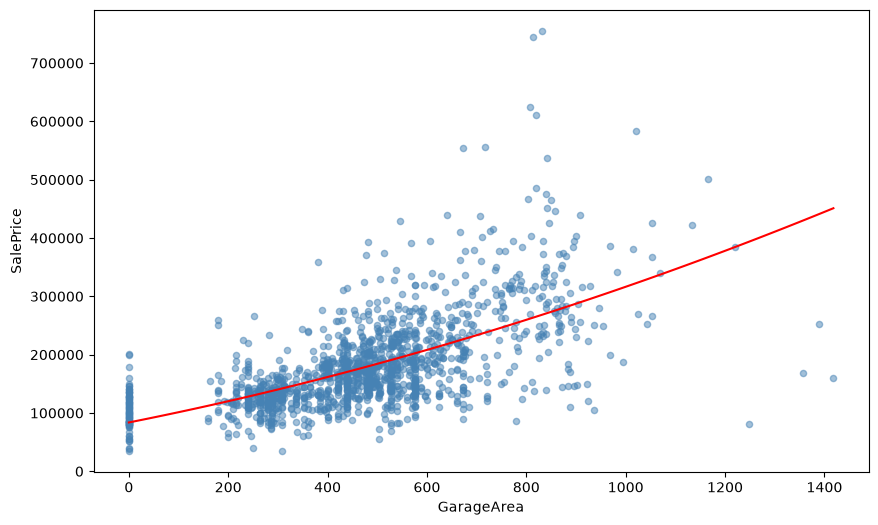

In [21]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="GarageArea",
    y="SalePrice",
    order=2,
    ci=None,
    scatter_kws={
        "alpha": 0.5,
        "s": 20,
        "color": "steelblue"
    },
    line_kws={
        "color": "red",
        "linewidth": 1.5
    }
)

**Nhận xét:** Biểu đồ so sánh diện tích gara (`GarageArea`) với giá bán. Xu hướng đi lên gợi ý gara rộng hơn có thể đi kèm giá bán cao hơn, nhưng mức độ phân tán của các điểm cho thấy diện tích gara không phải yếu tố duy nhất quyết định giá nhà.

## Ma trận tương quan giữa các biến số

Sử dụng hệ số tương quan Pearson để quan sát mức độ liên hệ tuyến tính giữa các biến số. Heatmap tập trung vào các biến có tương quan mạnh nhất với `SalePrice` để biểu đồ dễ đọc hơn.

Lưu ý: tương quan không đồng nghĩa với quan hệ nhân quả; các biến phân loại như `Neighborhood` và `HouseStyle` không được đưa trực tiếp vào ma trận Pearson.

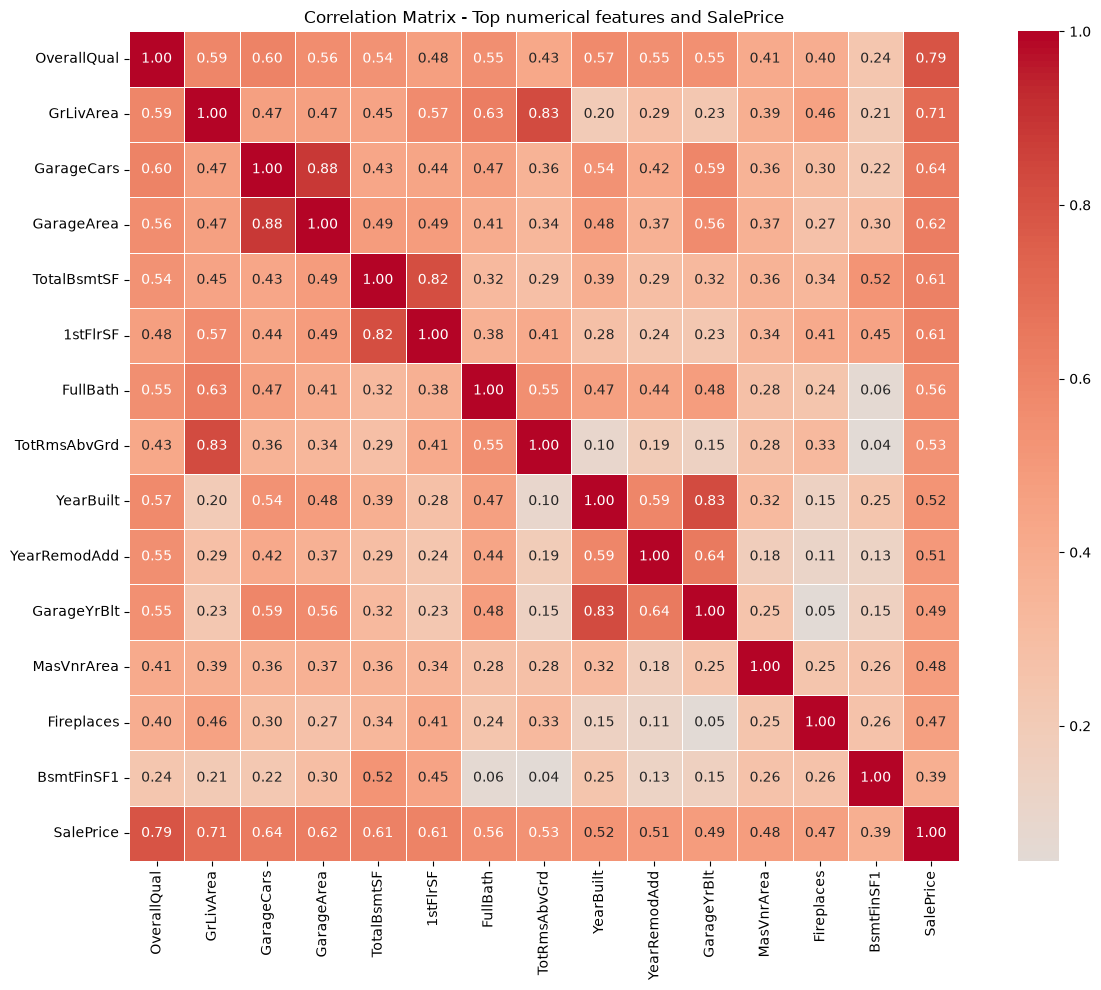

In [3]:
# Chọn các biến số và lấy những biến tương quan mạnh nhất với SalePrice
numeric_df = df.select_dtypes(include="number")
corr_matrix = numeric_df.corr(method="pearson")

top_corr_features = (
    corr_matrix["SalePrice"]
    .drop("SalePrice")
    .abs()
    .sort_values(ascending=False)
    .head(14)
    .index
    .tolist()
)

heatmap_features = top_corr_features + ["SalePrice"]
plt.figure(figsize=(13, 10))
sns.heatmap(
    corr_matrix.loc[heatmap_features, heatmap_features],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)
plt.title("Correlation Matrix - Top numerical features and SalePrice")
plt.tight_layout()
plt.show()

### Nhận xét – Heatmap tương quan

Heatmap giúp nhận diện nhanh các biến có liên hệ với `SalePrice` và các cặp biến đầu vào có thể chứa thông tin chồng lấn.

Ở phía biến mục tiêu, `OverallQual` và `GrLivArea` là hai biến nổi bật trong bảng tương quan trước đó; các biến liên quan đến gara và diện tích tầng hầm/tầng một cũng có tương quan dương đáng chú ý. Đây là những nhóm đặc trưng nên được xem xét kỹ hơn khi phân tích và xây dựng mô hình.

Khi nhìn giữa các biến đầu vào, cần chú ý các ô có trị tuyệt đối lớn. Nếu hai biến cùng tương quan cao với giá và cũng tương quan mạnh với nhau, chúng có thể mang thông tin tương tự. Điều này không bắt buộc phải loại một biến ngay, nhưng là tín hiệu để kiểm tra đa cộng tuyến hoặc so sánh hiệu quả mô hình khi dùng từng biến.

Kết luận từ heatmap chỉ phản ánh quan hệ tuyến tính trên tập dữ liệu hiện tại; cần kết hợp hiểu biết nghiệp vụ và đánh giá mô hình để lựa chọn đặc trưng.

## Phân tích giá nhà theo khu vực (Neighborhood)

So sánh số lượng căn nhà và mức giá bán theo từng khu vực. Sử dụng trung vị (`median`) bên cạnh trung bình (`mean`) vì giá nhà có thể xuất hiện ngoại lệ. Biểu đồ hộp giúp quan sát độ phân tán và các giá trị ngoại lệ trong từng khu vực.

In [4]:
# Tổng hợp giá bán theo khu vực
neighborhood_summary = (
    df.groupby("Neighborhood")["SalePrice"]
    .agg(
        so_luong="count",
        gia_trung_binh="mean",
        gia_trung_vi="median",
        gia_thap_nhat="min",
        gia_cao_nhat="max"
    )
    .sort_values("gia_trung_vi", ascending=False)
)

display(neighborhood_summary.round(0))

,so_luong,gia_trung_binh,gia_trung_vi,gia_thap_nhat,gia_cao_nhat
Neighborhood,,,,,
NridgHt,77,316271.0,315000.0,154000,611657
NoRidge,41,335295.0,301500.0,190000,755000
StoneBr,25,310499.0,278000.0,170000,556581
Timber,38,242247.0,228475.0,137500,378500
Somerst,86,225380.0,225500.0,144152,423000
Veenker,11,238773.0,218000.0,162500,385000
Crawfor,51,210625.0,200624.0,90350,392500
ClearCr,28,212565.0,200250.0,130000,328000
CollgCr,150,197966.0,197200.0,110000,424870


### Nhận xét – Bảng thống kê theo `Neighborhood`

Bảng cho thấy sự khác biệt đáng kể về giá bán giữa các khu vực:

- `NoRidge` có giá trung bình cao nhất trong bảng (khoảng **335.295**), trong khi `NridgHt` có trung vị cao nhất (khoảng **315.000**). Hai thước đo không nhất thiết xếp hạng khu vực giống nhau vì trung bình nhạy với các căn nhà có giá rất cao.
- `StoneBr` cũng có trung vị cao (khoảng **278.000**), tiếp theo là `Timber` (khoảng **228.475**) và `Somerst` (khoảng **225.500**).
- Ở phía thấp, `MeadowV` có trung vị khoảng **88.000**, `IDOTRR` khoảng **103.000**, và `BrDale` khoảng **106.000**.
- Số lượng mẫu giữa các khu vực không đồng đều. Chẳng hạn `NAmes` có **225** căn và `CollgCr` có **150** căn, trong khi `Blueste` chỉ có **2** căn. Vì vậy, mức trung vị của các khu vực có ít quan sát cần được diễn giải thận trọng.

Kết quả gợi ý khu vực có thể là đặc trưng quan trọng khi dự đoán giá. Tuy nhiên, sự khác biệt giá giữa các khu vực có thể đồng thời phản ánh khác biệt về chất lượng, diện tích và loại nhà; bảng này chưa tách riêng ảnh hưởng của từng yếu tố.

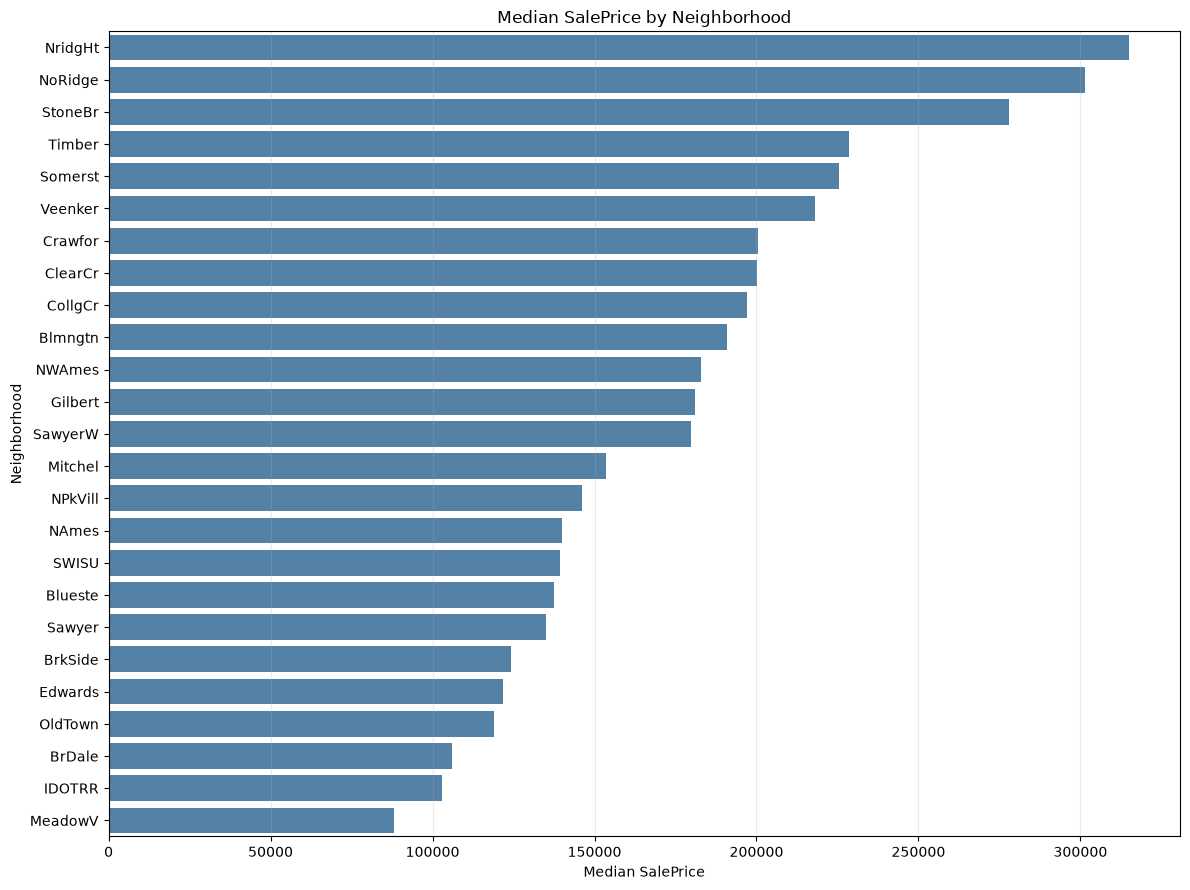

In [5]:
# Biểu đồ trung vị giá bán theo khu vực
plt.figure(figsize=(12, 9))
sns.barplot(
    data=neighborhood_summary.reset_index(),
    x="gia_trung_vi",
    y="Neighborhood",
    color="steelblue"
)
plt.title("Median SalePrice by Neighborhood")
plt.xlabel("Median SalePrice")
plt.ylabel("Neighborhood")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### Nhận xét – So sánh trung vị giá theo khu vực

Biểu đồ cột sắp xếp các khu vực theo trung vị `SalePrice`, giúp nhìn rõ thứ hạng mặt bằng giá điển hình:

- Các khu vực như `NridgHt`, `NoRidge` và `StoneBr` nằm ở nhóm trung vị cao.
- `Timber`, `Somerst` và `Veenker` cũng có mức trung vị tương đối cao so với nhiều khu vực còn lại.
- `MeadowV`, `IDOTRR` và `BrDale` nằm ở nhóm trung vị thấp.

Khoảng cách giữa các thanh thể hiện chênh lệch về trung vị giá bán giữa các khu vực. Đây là so sánh mô tả, không có nghĩa mọi căn nhà trong khu vực có trung vị cao đều đắt hơn mọi căn nhà ở khu vực khác. Cần đối chiếu thêm boxplot để xem mức độ chồng lấn và biến động giá trong từng khu vực.

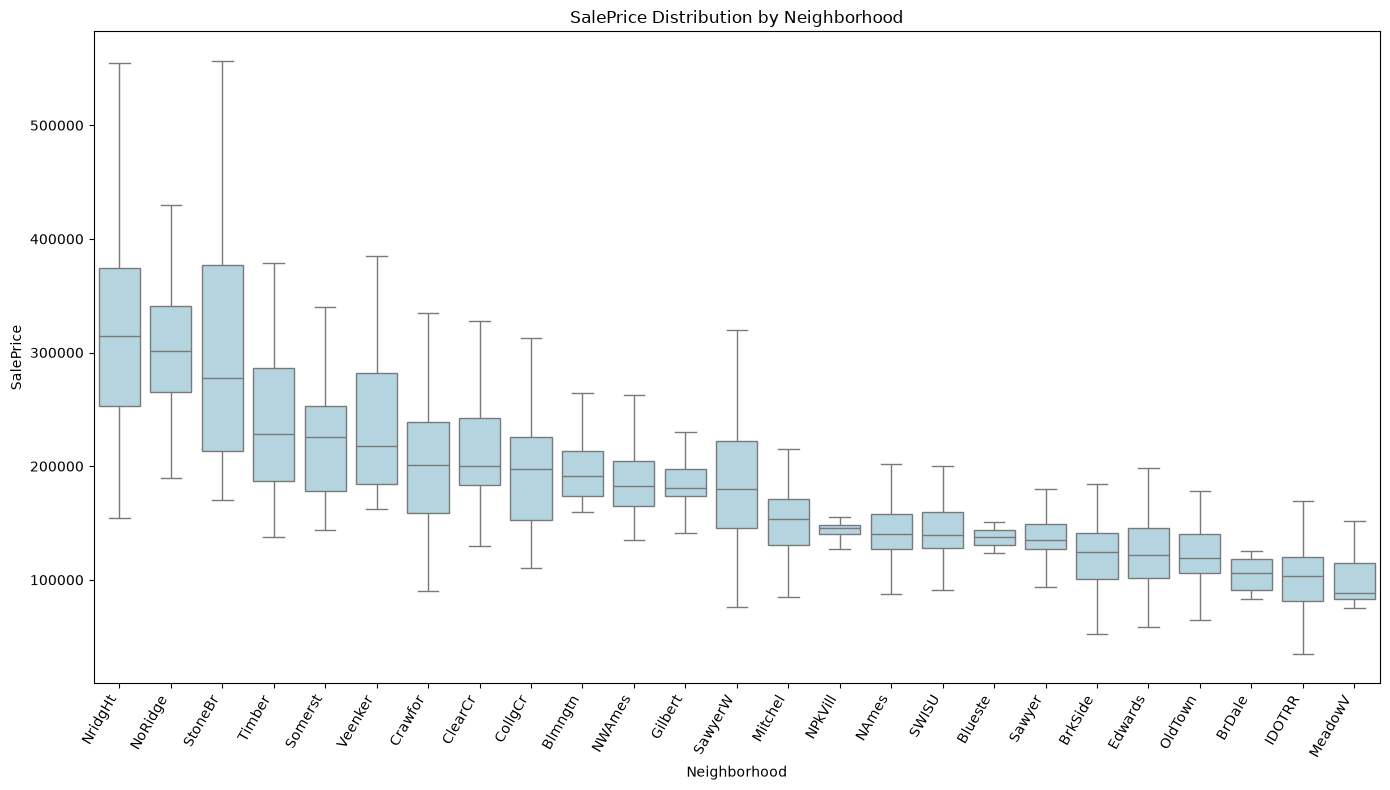

Khu vực có trung vị giá bán cao nhất: NridgHt
Khu vực có trung vị giá bán thấp nhất: MeadowV


In [6]:
# Phân phối giá bán theo khu vực
neighborhood_order = neighborhood_summary.index.tolist()
plt.figure(figsize=(14, 8))
sns.boxplot(
    data=df,
    x="Neighborhood",
    y="SalePrice",
    order=neighborhood_order,
    color="lightblue",
    showfliers=False
)
plt.title("SalePrice Distribution by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("SalePrice")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

print("Khu vực có trung vị giá bán cao nhất:", neighborhood_summary.index[0])
print("Khu vực có trung vị giá bán thấp nhất:", neighborhood_summary.index[-1])

### Nhận xét – Phân phối giá theo khu vực (Boxplot)

Boxplot bổ sung thông tin mà biểu đồ trung vị không thể hiện đầy đủ:

- Đường nằm giữa hộp là trung vị của khu vực.
- Chiều cao hộp thể hiện khoảng tứ phân vị (IQR), tức vùng chứa 50% quan sát ở giữa.
- Râu biểu thị phạm vi theo quy tắc của boxplot; các điểm nằm ngoài râu được đánh dấu là quan sát ngoại lệ theo quy tắc này, không mặc nhiên là dữ liệu sai.

Khi so sánh các khu vực, cần xem đồng thời vị trí trung vị, độ rộng hộp và số điểm ngoại lệ. Khu vực có trung vị cao nhưng hộp rộng có thể có mức giá biến động lớn; hai khu vực có trung vị khác nhau vẫn có thể có các khoảng giá chồng lấn.

Nên đối chiếu boxplot với bảng thống kê và biểu đồ trung vị phía trên. Đặc biệt, các khu vực có ít mẫu có thể tạo ra hình dạng hộp thiếu ổn định.

## Phân tích theo chất lượng tổng thể (OverallQual)

`OverallQual` là thang đánh giá chất lượng tổng thể của căn nhà. Phân tích giá bán theo từng mức chất lượng để xem giá nhà thay đổi như thế nào giữa các nhóm. Bảng thống kê gồm số lượng, giá trung bình và trung vị; biểu đồ hộp thể hiện độ phân tán của giá bán.

In [7]:
quality_summary = (
    df.groupby("OverallQual")["SalePrice"]
    .agg(
        so_luong="count",
        gia_trung_binh="mean",
        gia_trung_vi="median",
        gia_thap_nhat="min",
        gia_cao_nhat="max"
    )
    .sort_index()
)

display(quality_summary.round(0))

,so_luong,gia_trung_binh,gia_trung_vi,gia_thap_nhat,gia_cao_nhat
OverallQual,,,,,
1,2,50150.0,50150.0,39300,61000
2,3,51770.0,60000.0,35311,60000
3,20,87474.0,86250.0,37900,139600
4,116,108421.0,108000.0,34900,256000
5,397,133523.0,133000.0,55993,228950
6,374,161603.0,160000.0,76000,277000
7,319,207716.0,200141.0,82500,383970
8,168,274736.0,269750.0,122000,538000
9,43,367513.0,345000.0,239000,611657


### Nhận xét – Bảng thống kê theo `OverallQual`

Bảng thể hiện xu hướng tăng rõ rệt của giá bán khi điểm chất lượng tổng thể tăng:

- Trung vị tăng từ khoảng **50.150** ở mức điểm 1 lên **160.000** ở mức 6, **200.141** ở mức 7 và **269.750** ở mức 8.
- Hai mức điểm cao nhất có trung vị lần lượt khoảng **345.000** (mức 9) và **432.390** (mức 10).
- Nhóm điểm 5 và 6 có số lượng mẫu lớn nhất (lần lượt **397** và **374** căn), trong khi mức 1 chỉ có **2** căn, mức 2 có **3** căn và mức 10 có **18** căn.

Như vậy, dữ liệu cho thấy mối liên hệ thuận mạnh giữa `OverallQual` và `SalePrice`, phù hợp với hệ số tương quan Pearson khoảng **0,791**. Tuy nhiên, không nên so sánh mức điểm có quá ít mẫu với cùng độ tin cậy như nhóm có hàng trăm quan sát. Ngoài ra, giá trong cùng một mức chất lượng vẫn có khoảng dao động lớn, do các đặc trưng khác cũng ảnh hưởng đến giá.

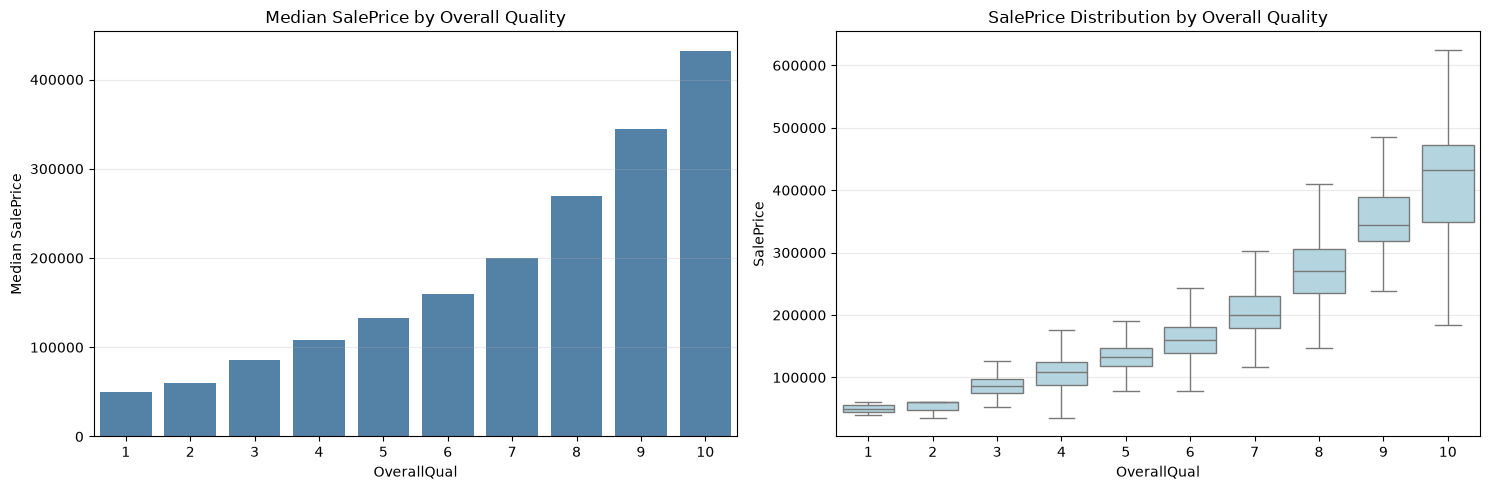

Mức OverallQual có trung vị giá bán cao nhất: 10
Mức OverallQual có trung vị giá bán thấp nhất: 1


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=quality_summary.reset_index(),
    x="OverallQual",
    y="gia_trung_vi",
    color="steelblue",
    ax=axes[0]
)
axes[0].set_title("Median SalePrice by Overall Quality")
axes[0].set_xlabel("OverallQual")
axes[0].set_ylabel("Median SalePrice")
axes[0].grid(axis="y", alpha=0.25)

sns.boxplot(
    data=df,
    x="OverallQual",
    y="SalePrice",
    color="lightblue",
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title("SalePrice Distribution by Overall Quality")
axes[1].set_xlabel("OverallQual")
axes[1].set_ylabel("SalePrice")
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()
print("Mức OverallQual có trung vị giá bán cao nhất:", quality_summary["gia_trung_vi"].idxmax())
print("Mức OverallQual có trung vị giá bán thấp nhất:", quality_summary["gia_trung_vi"].idxmin())

### Nhận xét – Biểu đồ giá theo `OverallQual`

Biểu đồ bên trái thể hiện trung vị giá bán theo từng mức chất lượng; biểu đồ hộp bên phải cho thấy phân phối giá bên trong mỗi nhóm.

Xu hướng trung vị tăng theo điểm chất lượng là bằng chứng trực quan củng cố nhận xét từ bảng thống kê: nhà có chất lượng tổng thể cao thường được bán với giá cao hơn. Boxplot cũng cho thấy trong cùng một mức điểm vẫn tồn tại chênh lệch giá đáng kể; một số căn nhà ở nhóm điểm trung bình có thể có giá cao, và một số căn ở nhóm điểm cao vẫn có giá thấp hơn các căn khác cùng nhóm.

Do đó, `OverallQual` là biến rất đáng chú ý cho bài toán dự đoán `SalePrice`, nhưng nên kết hợp với diện tích, khu vực, năm xây dựng và các tiện ích khác. Các nhóm có ít quan sát (đặc biệt điểm 1, 2 và 10) cần được diễn giải thận trọng.

## Phân tích theo kiểu thiết kế nhà (HouseStyle)

So sánh giá bán giữa các kiểu thiết kế nhà (`HouseStyle`). Do số lượng mẫu giữa các kiểu có thể không đồng đều, cần xem đồng thời số lượng quan sát và trung vị giá bán, tránh kết luận chỉ dựa trên giá trung bình.

In [9]:
style_summary = (
    df.groupby("HouseStyle")["SalePrice"]
    .agg(
        so_luong="count",
        gia_trung_binh="mean",
        gia_trung_vi="median",
        gia_thap_nhat="min",
        gia_cao_nhat="max"
    )
    .sort_values("gia_trung_vi", ascending=False)
)

display(style_summary.round(0))

,so_luong,gia_trung_binh,gia_trung_vi,gia_thap_nhat,gia_cao_nhat
HouseStyle,,,,,
2.5Fin,8,220000.0,194000.0,104000,475000
2Story,445,210052.0,190000.0,40000,755000
SLvl,65,166703.0,164500.0,91000,345000
1Story,726,175985.0,154750.0,34900,611657
SFoyer,37,135074.0,135960.0,75500,206300
2.5Unf,11,157355.0,133900.0,101000,325000
1.5Fin,154,143117.0,132000.0,37900,410000
1.5Unf,14,110150.0,111250.0,76000,139400


### Nhận xét – Bảng thống kê theo `HouseStyle`

Số lượng mẫu tập trung chủ yếu ở hai kiểu `1Story` (**726** căn) và `2Story` (**445** căn); các kiểu còn lại có số lượng nhỏ hơn nhiều.

Một số điểm đáng chú ý:
- `2.5Fin` có trung vị khoảng **194.000**, cao nhất trong các kiểu nhà ở bảng này; tuy nhiên chỉ có **8** quan sát nên cần thận trọng khi khái quát.
- `2Story` có trung vị khoảng **190.000** với **445** quan sát, vì vậy kết quả của nhóm này dựa trên quy mô mẫu lớn hơn nhiều.
- `SLvl` có trung vị khoảng **164.500**; `1Story` khoảng **154.750**.
- `1.5Fin` và `2.5Unf` có trung vị lần lượt khoảng **132.000** và **133.900**; `1.5Unf` khoảng **111.250**.

Giá trung bình và trung vị có thể khác nhau do phân phối giá và các giá trị cực trị. Khi đánh giá kiểu nhà, nên ưu tiên xem trung vị cùng số lượng mẫu, sau đó dùng boxplot để kiểm tra độ phân tán.**Nhận xét:** Bảng cho biết số lượng và thống kê giá bán theo kiểu thiết kế nhà (`HouseStyle`). So sánh trung vị để nhận biết kiểu nhà có mức giá điển hình cao hoặc thấp; đồng thời xem số lượng mẫu để tránh diễn giải quá mức đối với kiểu nhà xuất hiện ít.

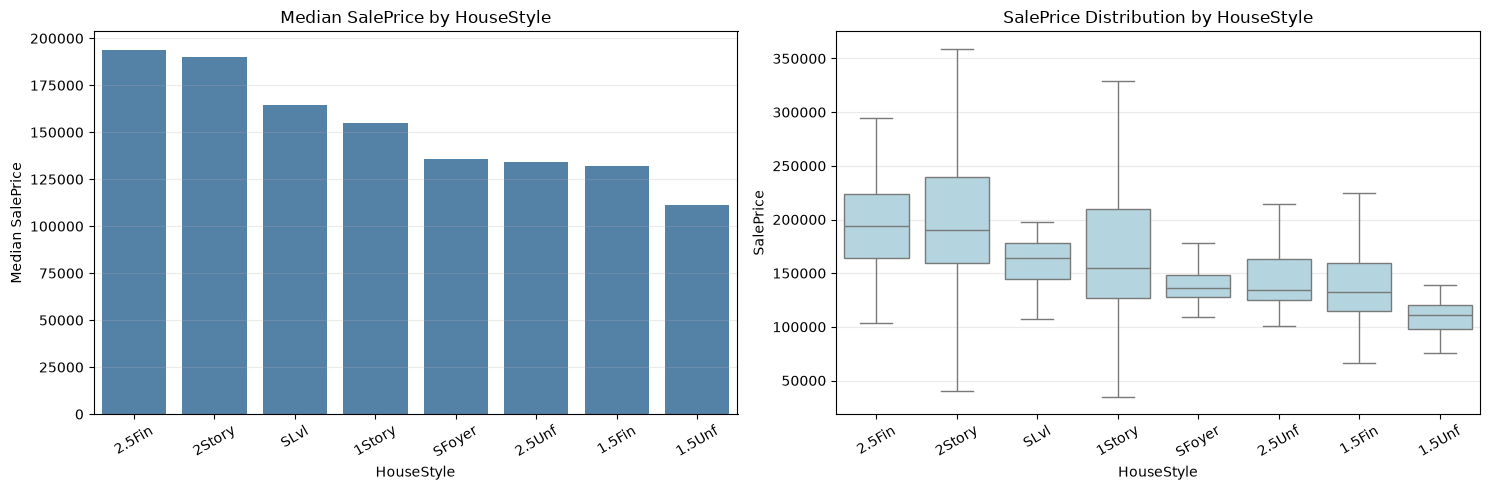

Kiểu nhà có trung vị giá bán cao nhất: 2.5Fin
Kiểu nhà có trung vị giá bán thấp nhất: 1.5Unf


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=style_summary.reset_index(),
    x="HouseStyle",
    y="gia_trung_vi",
    color="steelblue",
    ax=axes[0]
)
axes[0].set_title("Median SalePrice by HouseStyle")
axes[0].set_xlabel("HouseStyle")
axes[0].set_ylabel("Median SalePrice")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(axis="y", alpha=0.25)

style_order = style_summary.index.tolist()
sns.boxplot(
    data=df,
    x="HouseStyle",
    y="SalePrice",
    order=style_order,
    color="lightblue",
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title("SalePrice Distribution by HouseStyle")
axes[1].set_xlabel("HouseStyle")
axes[1].set_ylabel("SalePrice")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()
print("Kiểu nhà có trung vị giá bán cao nhất:", style_summary.index[0])
print("Kiểu nhà có trung vị giá bán thấp nhất:", style_summary.index[-1])

### Nhận xét – Biểu đồ giá theo `HouseStyle`

Biểu đồ cột bên trái xếp hạng trung vị giá bán giữa các kiểu thiết kế; boxplot bên phải cho biết mức độ phân tán giá trong từng kiểu.

Kết quả nhìn chung phù hợp với bảng thống kê: `2.5Fin` và `2Story` nằm ở nhóm có trung vị cao; `1.5Unf` và `1.5Fin` có trung vị thấp hơn. Tuy nhiên, `2.5Fin` chỉ có 8 căn, nên thứ hạng trung vị của nhóm này có thể thay đổi đáng kể nếu có thêm quan sát. `2Story` có 445 căn, do đó ước lượng trung vị của nhóm dựa trên nhiều dữ liệu hơn.

Boxplot cần được đọc cùng trung vị và số lượng mẫu: hộp/râu dài cho thấy giá biến động rộng; các điểm nằm ngoài râu là ngoại lệ theo quy tắc hiển thị, không tự động là dữ liệu lỗi. Các khoảng giá giữa các kiểu nhà có thể chồng lấn, vì giá bán còn phụ thuộc vào chất lượng, diện tích, khu vực và tuổi căn nhà.

**Kết luận:** `HouseStyle` có thể cung cấp thông tin hữu ích cho phân tích và mô hình hóa, nhưng không nên dùng riêng biến này để suy ra giá bán. Cần mã hóa biến phân loại phù hợp và đánh giá mức đóng góp của nó trong mô hình cùng các đặc trưng khác.**Nhận xét:** Biểu đồ bên trái xếp hạng trung vị giá bán theo kiểu nhà; biểu đồ hộp bên phải thể hiện độ phân tán giá trong từng kiểu. So sánh hai biểu đồ để phân biệt kiểu nhà có trung vị cao với kiểu nhà có mức giá biến động lớn. Kết quả cần được xem cùng số lượng mẫu trong bảng.